Aim: Data Visualization using matplotlib 
Problem Statement: Analyzing Air Quality Index (AQI) Trends in a City 
Dataset: "City_Air_Quality.csv" 
Description: The dataset contains information about air quality measurements in a specific city over a 
period of time. It includes attributes such as date, time, pollutant levels (e.g., PM2.5, PM10, CO), and the 
Air Quality Index (AQI) values. The goal is to use the matplotlib library to create visualizations that 
effectively represent the AQI trends and patterns for different pollutants in the city. 



Name:Aditya Rade
Roll.No:BEAD23167

Outputs:

Step 1 — Import and Load Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

data = pd.read_csv("Delhi_AQI_Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

display(data.head())

Dataset loaded successfully!
Shape: (2191, 11)

Columns:
['City', 'Date', 'AQI', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Unnamed: 9', 'Unnamed: 10']


,City,Date,AQI,PM2.5,PM10,NO2,SO2,CO,O3,Unnamed: 9,Unnamed: 10
0,Delhi,01/01/18,406,223.3,438.48,336.98,462.84,4.26,385.7,NaN,NaN
1,Delhi,02/01/18,418,229.9,451.44,346.94,476.52,4.39,397.1,NaN,NaN
2,Delhi,03/01/18,382,210.1,412.56,317.06,435.48,4.01,362.9,NaN,NaN
3,Delhi,04/01/18,366,201.3,395.28,303.78,417.24,3.84,347.7,NaN,NaN
4,Delhi,05/01/18,390,214.5,421.20,323.70,444.60,4.10,370.5,NaN,NaN


Step 2 — Clean and Prepare Data

In [5]:
# Clean column names
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print("Cleaned Columns:")
print(data.columns.tolist())

# Find date column
date_col = None

for col in data.columns:
    if "date" in col or "time" in col:
        date_col = col
        break

print("\nDate column:", date_col)

# Convert date column
if date_col:
    data[date_col] = pd.to_datetime(data[date_col], errors="coerce")

# Convert possible numeric columns
for col in data.columns:
    if col != date_col:
        data[col] = pd.to_numeric(data[col], errors="ignore")

# Fill missing numerical values
numeric_cols = data.select_dtypes(include=np.number).columns

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

print("\nMissing values after cleaning:")
print(data.isnull().sum())

Cleaned Columns:
['city', 'date', 'aqi', 'pm2.5', 'pm10', 'no2', 'so2', 'co', 'o3', 'unnamed:_9', 'unnamed:_10']

Date column: date


C:\Users\adity\AppData\Local\Temp\ipykernel_27096\250880026.py:25: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[date_col] = pd.to_datetime(data[date_col], errors="coerce")
C:\Users\adity\AppData\Local\Temp\ipykernel_27096\250880026.py:30: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  data[col] = pd.to_numeric(data[col], errors="ignore")



Missing values after cleaning:
city              0
date              0
aqi               0
pm2.5             0
pm10              0
no2               0
so2               0
co                0
o3                0
unnamed:_9     2191
unnamed:_10    2191
dtype: int64


c:\Users\adity\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\adity\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


Step 3 — Plot AQI Trend

AQI column: aqi


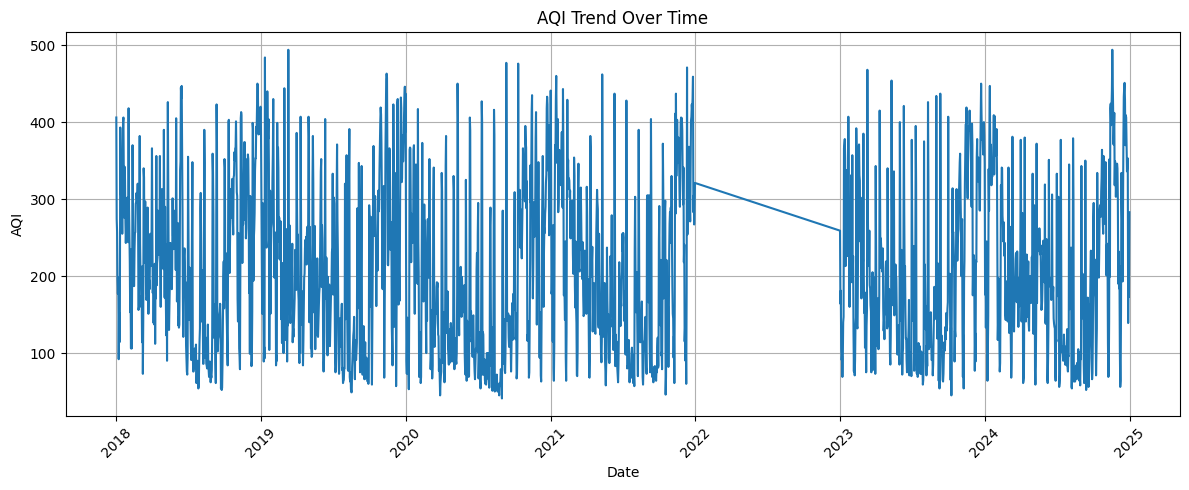

In [8]:
# Find AQI column
aqi_col = None

for col in data.columns:
    if "aqi" in col:
        aqi_col = col
        break

print("AQI column:", aqi_col)

if aqi_col and date_col:

    temp = data[[date_col, aqi_col]].dropna()
    temp = temp.sort_values(date_col)

    plt.figure(figsize=(12, 5))

    plt.plot(temp[date_col], temp[aqi_col])

    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.title("AQI Trend Over Time")
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

else:
    print("AQI or Date column not found.")
    print("Name: Aditya Rade  Roll.No:BEAD23167")

Step 4 — Pollutant Levels Over Time

Pollutants found: ['pm10', 'no2', 'so2', 'co', 'o3']


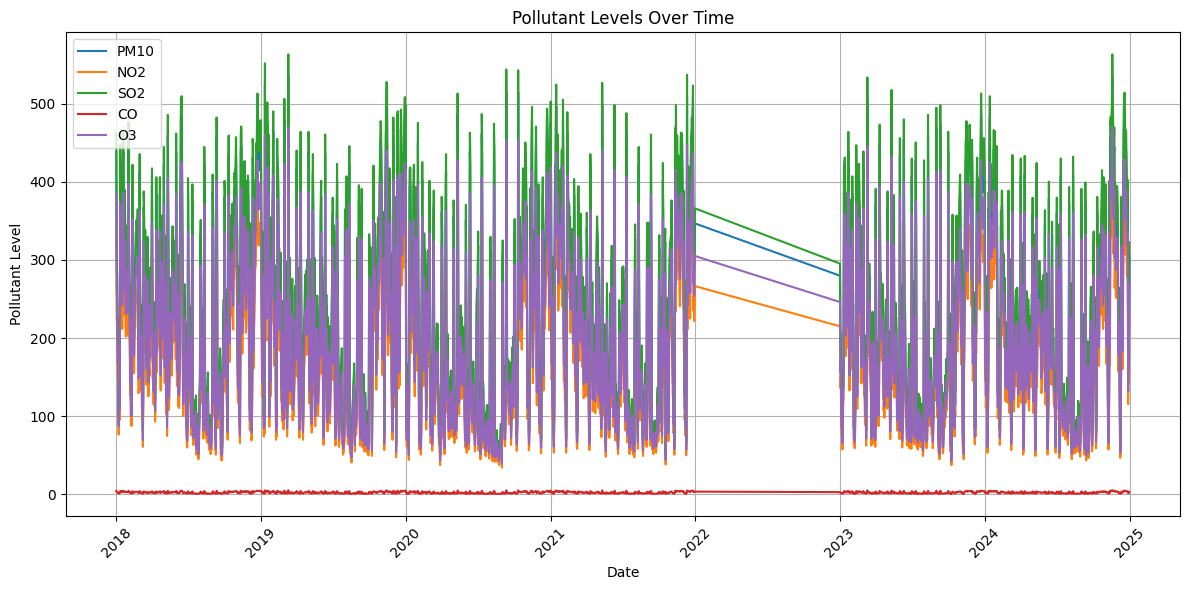

In [10]:
# Detect pollutant columns
pollutant_names = [
    "pm2_5", "pm25", "pm10",
    "no2", "so2", "co", "o3"
]

pollutants = []

for col in data.columns:
    if col in pollutant_names:
        pollutants.append(col)

print("Pollutants found:", pollutants)

if date_col and len(pollutants) > 0:

    plt.figure(figsize=(12, 6))

    for col in pollutants:
        temp = data[[date_col, col]].dropna()
        temp = temp.sort_values(date_col)

        plt.plot(
            temp[date_col],
            temp[col],
            label=col.upper()
        )

    plt.xlabel("Date")
    plt.ylabel("Pollutant Level")
    plt.title("Pollutant Levels Over Time")
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

else:
    print("No suitable pollutant columns found.")
    print("Name: Aditya Rade  Roll.No:BEAD23167")

Step 5 — AQI Distribution and AQI vs Pollutant

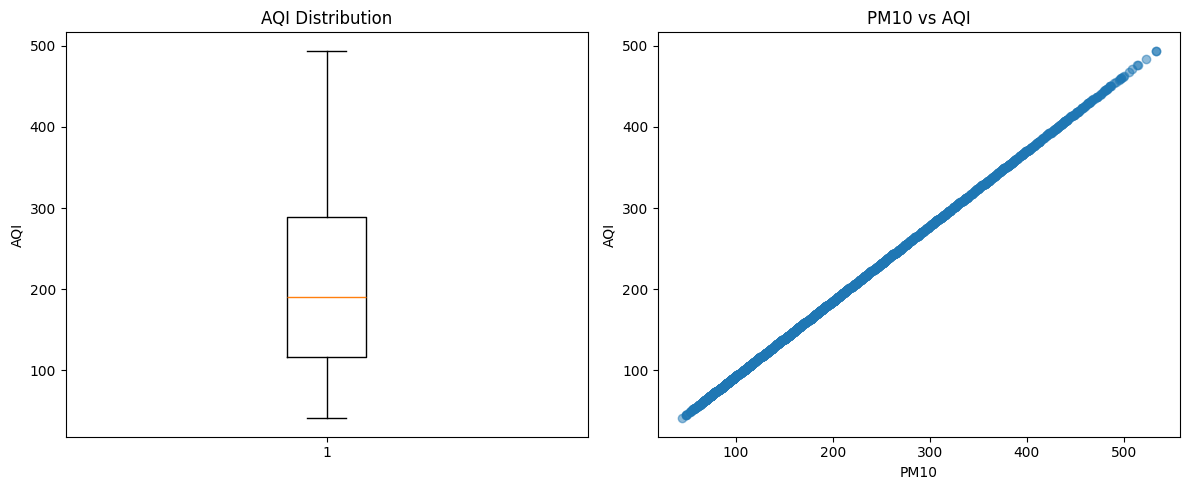

In [12]:
if aqi_col:

    plt.figure(figsize=(12, 5))

    # AQI distribution
    plt.subplot(1, 2, 1)

    aqi_values = data[aqi_col].dropna()

    plt.boxplot(aqi_values)
    plt.ylabel("AQI")
    plt.title("AQI Distribution")

    # AQI vs pollutant
    plt.subplot(1, 2, 2)

    if len(pollutants) > 0:

        pollutant = pollutants[0]

        temp = data[[pollutant, aqi_col]].dropna()

        plt.scatter(
            temp[pollutant],
            temp[aqi_col],
            alpha=0.5
        )

        plt.xlabel(pollutant.upper())
        plt.ylabel("AQI")
        plt.title(pollutant.upper() + " vs AQI")

    else:
        plt.text(
            0.5, 0.5,
            "No pollutant data available",
            ha="center",
            va="center"
        )

    plt.tight_layout()
    plt.show()

else:
    print("AQI column not found.")
    
    print("Name: Aditya Rade Roll.No:BEAD23167")